# FlowA11y v5 binary publication analysis

This notebook reproduces the reported binary defect-decision analysis from saved normalized tables. It does not launch a browser and does not call Gemini.

The fixed evaluation frame contains **765 scenario--criterion rows**: 17 completed scenarios and 45 WCAG criteria per scenario. `FAIL` maps to `TRIGGER`; `WARNING`, `PASS`, `NOT_APPLICABLE`, and `INCOMPLETE` map to `NOT_TRIGGER`. `NOT_TRIGGER` means no automatic defect report from the observed trace. It does not verify accessibility compliance.

In [1]:
from pathlib import Path
import sys
import pandas as pd

project_root = next(
    candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (candidate / "benchmarking").is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from IPython.display import Image, Markdown, display

from benchmarking.dynamic.publication_binary_analysis import run_analysis

analysis = run_analysis()
tables = analysis["tables"]
output_dir = analysis["output_dir"]

display(Markdown(
    "The analysis loaded 32 saved CSV inputs and produced 20 validated 765-row "
    "method/run matrices. Derived files were written to a temporary directory by default; "
    "set `FLOWA11Y_PUBLICATION_OUTPUT_DIR` to override it."
))
display(tables["binary_repeat_summary"])

The analysis loaded 32 saved CSV inputs and produced 20 validated 765-row method/run matrices. Derived files were written to a temporary directory by default; set `FLOWA11Y_PUBLICATION_OUTPUT_DIR` to override it.

,cohort,cohort_id,method,method_id,method_role,runs,rows_per_run,mean_TP,sd_TP,mean_FP,...,mean_specificity,sd_specificity,mean_balanced_accuracy,sd_balanced_accuracy,mean_accuracy,sd_accuracy,mean_predicted_trigger_rate,sd_predicted_trigger_rate,mean_predicted_not_trigger_rate,sd_predicted_not_trigger_rate
0,Original naive comparison,naive,FlowA11y,gemini-dynamic-wcag,primary,4,765,21.500000,2.645751,61.500000,...,0.916213,0.010346,0.804880,0.041158,0.907190,0.009305,0.108497,0.011594,0.891503,0.011594
1,Original naive comparison,naive,Naive baseline,naive-browser-use-global-audit,comparator,4,765,0.250000,0.500000,4.750000,...,0.993529,0.004768,0.500797,0.007846,0.953595,0.004465,0.006536,0.004773,0.993464,0.004773
2,Baseline 2.0 matched trace,baseline_2,FlowA11y,gemini-dynamic-wcag,primary,3,765,20.000000,1.732051,53.666667,...,0.926885,0.006438,0.786023,0.024799,0.915468,0.003994,0.096296,0.008404,0.903704,0.008404
3,Baseline 2.0 matched trace,baseline_2,Baseline 2.0,baseline-2.0-matched-trace-generic-judge,comparator,3,765,13.000000,2.645751,53.000000,...,0.927793,0.006243,0.673574,0.044672,0.907190,0.008572,0.086275,0.004713,0.913725,0.004713
4,Baseline 3.0 global-evidence ablation,baseline_3,FlowA11y,gemini-dynamic-wcag,primary,3,765,19.333333,1.154701,56.000000,...,0.923706,0.002725,0.773681,0.018674,0.911547,0.003019,0.098475,0.003019,0.901525,0.003019
5,Baseline 3.0 global-evidence ablation,baseline_3,Baseline 3.0,baseline-3.0-matched-global-evidence-ablation,comparator,3,765,18.666667,2.081666,63.000000,...,0.914169,0.006812,0.758160,0.036107,0.901525,0.008704,0.106754,0.004949,0.893246,0.004949


## Mapping and validation

Every original tool and oracle status is mapped exactly once. The retained `not_trigger_reason` distinguishes weak signal, assessed pass, non-applicability, and insufficient evidence.

In [2]:
display(tables["binary_mapping_contract"])
display(tables["binary_mapping_validation"])

assert len(tables["binary_decision_rows"]) == 15_300
assert len(tables["binary_mapping_validation"]) == 20
assert tables["binary_mapping_validation"]["all_rows_mapped_exactly_once"].eq(1).all()

,original_status,binary_decision,not_trigger_reason
0,FAIL,TRIGGER,
1,WARNING,NOT_TRIGGER,weak_signal
2,PASS,NOT_TRIGGER,assessed_pass
3,NOT_APPLICABLE,NOT_TRIGGER,not_applicable
4,INCOMPLETE,NOT_TRIGGER,insufficient_evidence


,cohort,cohort_id,run,method,method_id,method_role,required_denominator,row_count,unique_primary_keys,tool_statuses_mapped,oracle_statuses_mapped,not_trigger_reasons_complete,trigger_reasons_blank,source_tool_scored_rows,source_tool_unscored_rows,all_rows_mapped_exactly_once
0,Original naive comparison,naive,Run 1,FlowA11y,gemini-dynamic-wcag,primary,765,765,765,1,1,1,1,675,90,1
1,Original naive comparison,naive,Run 1,Naive baseline,naive-browser-use-global-audit,comparator,765,765,765,1,1,1,1,675,90,1
2,Original naive comparison,naive,Run 2,FlowA11y,gemini-dynamic-wcag,primary,765,765,765,1,1,1,1,675,90,1
3,Original naive comparison,naive,Run 2,Naive baseline,naive-browser-use-global-audit,comparator,765,765,765,1,1,1,1,675,90,1
4,Original naive comparison,naive,Run 3,FlowA11y,gemini-dynamic-wcag,primary,765,765,765,1,1,1,1,720,45,1
5,Original naive comparison,naive,Run 3,Naive baseline,naive-browser-use-global-audit,comparator,765,765,765,1,1,1,1,720,45,1
6,Original naive comparison,naive,Run 4,FlowA11y,gemini-dynamic-wcag,primary,765,765,765,1,1,1,1,720,45,1
7,Original naive comparison,naive,Run 4,Naive baseline,naive-browser-use-global-audit,comparator,765,765,765,1,1,1,1,720,45,1
8,Baseline 2.0 matched trace,baseline_2,Run 1,FlowA11y,gemini-dynamic-wcag,primary,765,765,765,1,1,1,1,585,180,1
9,Baseline 2.0 matched trace,baseline_2,Run 1,Baseline 2.0,baseline-2.0-matched-trace-generic-judge,comparator,765,765,765,1,1,1,1,585,180,1


## Binary performance

Each confusion matrix uses `TRIGGER` versus `NOT_TRIGGER`. The reported metrics are precision, recall, F1, MCC, specificity, balanced accuracy, and ordinary accuracy.

In [3]:
display(tables["binary_metrics_by_run"])
display(tables["binary_confusion_counts"])
display(tables["binary_confusion_matrix"])
display(tables["binary_not_trigger_reason_repeat_summary"])

,cohort,cohort_id,run,method,method_id,method_role,denominator,TP,FP,TN,...,recall,f1,mcc,specificity,balanced_accuracy,accuracy,predicted_trigger_rate,predicted_not_trigger_rate,oracle_trigger_rate,oracle_not_trigger_rate
0,Original naive comparison,naive,Run 1,FlowA11y,gemini-dynamic-wcag,primary,765,18,54,680,...,0.580645,0.349515,0.342428,0.926431,0.753538,0.912418,0.094118,0.905882,0.040523,0.959477
1,Original naive comparison,naive,Run 1,Naive baseline,naive-browser-use-global-audit,comparator,765,1,6,728,...,0.032258,0.052632,0.049873,0.991826,0.512042,0.952941,0.009150,0.990850,0.040523,0.959477
2,Original naive comparison,naive,Run 2,FlowA11y,gemini-dynamic-wcag,primary,765,24,64,670,...,0.774194,0.403361,0.424571,0.912807,0.843500,0.907190,0.115033,0.884967,0.040523,0.959477
3,Original naive comparison,naive,Run 2,Naive baseline,naive-browser-use-global-audit,comparator,765,0,1,733,...,0.000000,0.000000,-0.007435,0.998638,0.499319,0.958170,0.001307,0.998693,0.040523,0.959477
4,Original naive comparison,naive,Run 3,FlowA11y,gemini-dynamic-wcag,primary,765,21,71,663,...,0.677419,0.341463,0.352023,0.903270,0.790345,0.894118,0.120261,0.879739,0.040523,0.959477
5,Original naive comparison,naive,Run 3,Naive baseline,naive-browser-use-global-audit,comparator,765,0,9,725,...,0.000000,0.000000,-0.022423,0.987738,0.493869,0.947712,0.011765,0.988235,0.040523,0.959477
6,Original naive comparison,naive,Run 4,FlowA11y,gemini-dynamic-wcag,primary,765,23,57,677,...,0.741935,0.414414,0.428045,0.922343,0.832139,0.915033,0.104575,0.895425,0.040523,0.959477
7,Original naive comparison,naive,Run 4,Naive baseline,naive-browser-use-global-audit,comparator,765,0,3,731,...,0.000000,0.000000,-0.012895,0.995913,0.497956,0.955556,0.003922,0.996078,0.040523,0.959477
8,Baseline 2.0 matched trace,baseline_2,Run 1,FlowA11y,gemini-dynamic-wcag,primary,765,19,50,684,...,0.612903,0.380000,0.374993,0.931880,0.772392,0.918954,0.090196,0.909804,0.040523,0.959477
9,Baseline 2.0 matched trace,baseline_2,Run 1,Baseline 2.0,baseline-2.0-matched-trace-generic-judge,comparator,765,12,58,676,...,0.387097,0.237624,0.210692,0.920981,0.654039,0.899346,0.091503,0.908497,0.040523,0.959477


,cohort,cohort_id,run,method,method_id,method_role,denominator,TP,FP,TN,FN
0,Original naive comparison,naive,Run 1,FlowA11y,gemini-dynamic-wcag,primary,765,18,54,680,13
1,Original naive comparison,naive,Run 1,Naive baseline,naive-browser-use-global-audit,comparator,765,1,6,728,30
2,Original naive comparison,naive,Run 2,FlowA11y,gemini-dynamic-wcag,primary,765,24,64,670,7
3,Original naive comparison,naive,Run 2,Naive baseline,naive-browser-use-global-audit,comparator,765,0,1,733,31
4,Original naive comparison,naive,Run 3,FlowA11y,gemini-dynamic-wcag,primary,765,21,71,663,10
5,Original naive comparison,naive,Run 3,Naive baseline,naive-browser-use-global-audit,comparator,765,0,9,725,31
6,Original naive comparison,naive,Run 4,FlowA11y,gemini-dynamic-wcag,primary,765,23,57,677,8
7,Original naive comparison,naive,Run 4,Naive baseline,naive-browser-use-global-audit,comparator,765,0,3,731,31
8,Baseline 2.0 matched trace,baseline_2,Run 1,FlowA11y,gemini-dynamic-wcag,primary,765,19,50,684,12
9,Baseline 2.0 matched trace,baseline_2,Run 1,Baseline 2.0,baseline-2.0-matched-trace-generic-judge,comparator,765,12,58,676,19


,cohort,cohort_id,run,method,method_id,method_role,oracle_binary_decision,tool_binary_decision,count
0,Original naive comparison,naive,Run 1,FlowA11y,gemini-dynamic-wcag,primary,TRIGGER,TRIGGER,18
1,Original naive comparison,naive,Run 1,FlowA11y,gemini-dynamic-wcag,primary,TRIGGER,NOT_TRIGGER,13
2,Original naive comparison,naive,Run 1,FlowA11y,gemini-dynamic-wcag,primary,NOT_TRIGGER,TRIGGER,54
3,Original naive comparison,naive,Run 1,FlowA11y,gemini-dynamic-wcag,primary,NOT_TRIGGER,NOT_TRIGGER,680
4,Original naive comparison,naive,Run 1,Naive baseline,naive-browser-use-global-audit,comparator,TRIGGER,TRIGGER,1
...,...,...,...,...,...,...,...,...,...
75,Baseline 3.0 global-evidence ablation,baseline_3,Run 3,FlowA11y,gemini-dynamic-wcag,primary,NOT_TRIGGER,NOT_TRIGGER,680
76,Baseline 3.0 global-evidence ablation,baseline_3,Run 3,Baseline 3.0,baseline-3.0-matched-global-evidence-ablation,comparator,TRIGGER,TRIGGER,21
77,Baseline 3.0 global-evidence ablation,baseline_3,Run 3,Baseline 3.0,baseline-3.0-matched-global-evidence-ablation,comparator,TRIGGER,NOT_TRIGGER,10
78,Baseline 3.0 global-evidence ablation,baseline_3,Run 3,Baseline 3.0,baseline-3.0-matched-global-evidence-ablation,comparator,NOT_TRIGGER,TRIGGER,58


,cohort,cohort_id,method,method_id,method_role,not_trigger_reason,runs,mean_count,sd_count,mean_share_of_not_trigger,sd_share_of_not_trigger,mean_share_of_765_rows,sd_share_of_765_rows
0,Original naive comparison,naive,FlowA11y,gemini-dynamic-wcag,primary,weak_signal,4,24.250000,7.088723,0.035639,0.010756,0.031699,0.009266
1,Original naive comparison,naive,FlowA11y,gemini-dynamic-wcag,primary,assessed_pass,4,156.500000,3.316625,0.229459,0.002650,0.204575,0.004335
2,Original naive comparison,naive,FlowA11y,gemini-dynamic-wcag,primary,not_applicable,4,285.250000,15.107945,0.418132,0.017787,0.372876,0.019749
3,Original naive comparison,naive,FlowA11y,gemini-dynamic-wcag,primary,insufficient_evidence,4,216.000000,9.309493,0.316770,0.014546,0.282353,0.012169
4,Original naive comparison,naive,Naive baseline,naive-browser-use-global-audit,comparator,weak_signal,4,3.750000,2.217356,0.004944,0.002935,0.004902,0.002899
5,Original naive comparison,naive,Naive baseline,naive-browser-use-global-audit,comparator,assessed_pass,4,31.500000,5.972158,0.041434,0.007750,0.041176,0.007807
6,Original naive comparison,naive,Naive baseline,naive-browser-use-global-audit,comparator,not_applicable,4,1.000000,1.414214,0.001322,0.001871,0.001307,0.001849
7,Original naive comparison,naive,Naive baseline,naive-browser-use-global-audit,comparator,insufficient_evidence,4,723.750000,6.344289,0.952300,0.006506,0.946078,0.008293
8,Baseline 2.0 matched trace,baseline_2,FlowA11y,gemini-dynamic-wcag,primary,weak_signal,3,25.000000,6.082763,0.036133,0.008578,0.032680,0.007951
9,Baseline 2.0 matched trace,baseline_2,FlowA11y,gemini-dynamic-wcag,primary,assessed_pass,3,156.666667,7.505553,0.226562,0.008829,0.204793,0.009811


## Derived report

The report and source manifest are written with the other derived outputs. The source manifest preserves the relative input path and SHA-256 digest for every saved table used in the calculation.

In [4]:
display(Markdown((output_dir / "binary_report.md").read_text(encoding="utf-8")))
display(tables["binary_source_manifest"])

derivation = pd.read_csv(output_dir / "binary_derivation_manifest.csv")
derivation_summary = (
    derivation.groupby(
        ["derived_artifact", "derivation_kind", "source_input_count"],
        as_index=False,
    )
    .size()
    .rename(columns={"size": "manifest_rows"})
)
display(Markdown("### Derived-output provenance"))
display(derivation_summary)

# Derived binary defect-decision report

This report derives binary decisions from saved five-status artifacts only. It does not rerun browser-use, Gemini, or any evaluation, and the original five-status artifacts remain unchanged.

The fixed evaluation frame contains 765 rows across 17 scenarios and 45 criteria per scenario. Every method/run is aligned to that same frame.

`TRIGGER` maps from `FAIL`. `NOT_TRIGGER` maps from `WARNING`, `PASS`, `NOT_APPLICABLE`, and `INCOMPLETE`. `NOT_TRIGGER` means no automatic defect report from the observed trace; it does not establish accessibility compliance.

| Cohort | Method | Runs | Precision | Recall | F1 | MCC | Balanced accuracy |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Original naive comparison | FlowA11y | 4 | 26.0% ± 2.6% | 69.4% ± 8.5% | 37.7% ± 3.7% | 38.7% ± 4.6% | 80.5% ± 4.1% |
| Original naive comparison | Naive baseline | 4 | 3.6% ± 7.1% | 0.8% ± 1.6% | 1.3% ± 2.6% | 0.2% ± 3.3% | 50.1% ± 0.8% |
| Baseline 2.0 matched trace | FlowA11y | 3 | 27.2% ± 0.4% | 64.5% ± 5.6% | 38.2% ± 1.0% | 38.2% ± 1.9% | 78.6% ± 2.5% |
| Baseline 2.0 matched trace | Baseline 2.0 | 3 | 19.7% ± 4.2% | 41.9% ± 8.5% | 26.8% ± 5.6% | 24.4% ± 6.4% | 67.4% ± 4.5% |
| Baseline 3.0 global-evidence ablation | FlowA11y | 3 | 25.7% ± 1.4% | 62.4% ± 3.7% | 36.4% ± 1.9% | 36.2% ± 2.3% | 77.4% ± 1.9% |
| Baseline 3.0 global-evidence ablation | Baseline 3.0 | 3 | 22.9% ± 3.2% | 60.2% ± 6.7% | 33.2% ± 4.3% | 33.0% ± 5.0% | 75.8% ± 3.6% |


,source_role,cohort,run,method,artifact_path,sha256
0,fixed evaluation oracle,V4 primary frame,V4 primary,All methods,benchmarking/dynamic/publication_results/v5/so...,0a7391db5b930f3efe92dc31bd8bd1027ab7a5ea31f5c3...
1,full oracle fixture validation,V4 primary frame,V4 primary,All methods,benchmarking/dynamic/publication_results/v5/so...,80925b8d53cd9906f69f9fbcf1ebc2bafef82560beb1fb...
2,stored five-status tool output,Original naive comparison,Run 1,FlowA11y,benchmarking/dynamic/publication_results/v5/so...,7d1875e247552bb71faff4ac818781456e369a832d3ce5...
3,native sparse oracle provenance,Original naive comparison,Run 1,FlowA11y,benchmarking/dynamic/publication_results/v5/so...,ff26e622ad26802e4bc3289423052221f9f59bf38bff69...
4,stored five-status tool output,Original naive comparison,Run 1,Naive baseline,benchmarking/dynamic/publication_results/v5/so...,3f3f3dd2552385c40a0ea3c7002cb11b3a637e9661d21e...
5,native sparse oracle provenance,Original naive comparison,Run 1,Naive baseline,benchmarking/dynamic/publication_results/v5/so...,ff26e622ad26802e4bc3289423052221f9f59bf38bff69...
6,stored five-status tool output,Original naive comparison,Run 2,FlowA11y,benchmarking/dynamic/publication_results/v5/so...,49329684e4bc46d439c9a731ad912a68d574d84a75d72a...
7,native sparse oracle provenance,Original naive comparison,Run 2,FlowA11y,benchmarking/dynamic/publication_results/v5/so...,d62793755d6042547a0bd235534d4b8a3464e517560ff2...
8,stored five-status tool output,Original naive comparison,Run 2,Naive baseline,benchmarking/dynamic/publication_results/v5/so...,374ccd005f37ac02755981c28996105f53309e2b3282e9...
9,native sparse oracle provenance,Original naive comparison,Run 2,Naive baseline,benchmarking/dynamic/publication_results/v5/so...,d62793755d6042547a0bd235534d4b8a3464e517560ff2...


### Derived-output provenance

,derived_artifact,derivation_kind,source_input_count,manifest_rows
0,binary_confusion_counts.csv,offline analysis transitive dependency,32,32
1,binary_confusion_matrix.csv,offline analysis transitive dependency,32,32
2,binary_decision_rows.csv,offline analysis transitive dependency,32,32
3,binary_derivation_manifest.csv,offline analysis transitive dependency,32,32
4,binary_mapping_contract.csv,static binary mapping contract,0,1
5,binary_mapping_validation.csv,offline analysis transitive dependency,32,32
6,binary_metrics_by_run.csv,offline analysis transitive dependency,32,32
7,binary_not_trigger_reason_repeat_summary.csv,offline analysis transitive dependency,32,32
8,binary_not_trigger_reasons.csv,offline analysis transitive dependency,32,32
9,binary_oracle_provenance.csv,offline analysis transitive dependency,32,32


## Publication figures

The figures compare binary performance, matched-input deltas, retained `NOT_TRIGGER` reasons, and automatic-report rates.

### `binary_metrics_by_cohort.png`

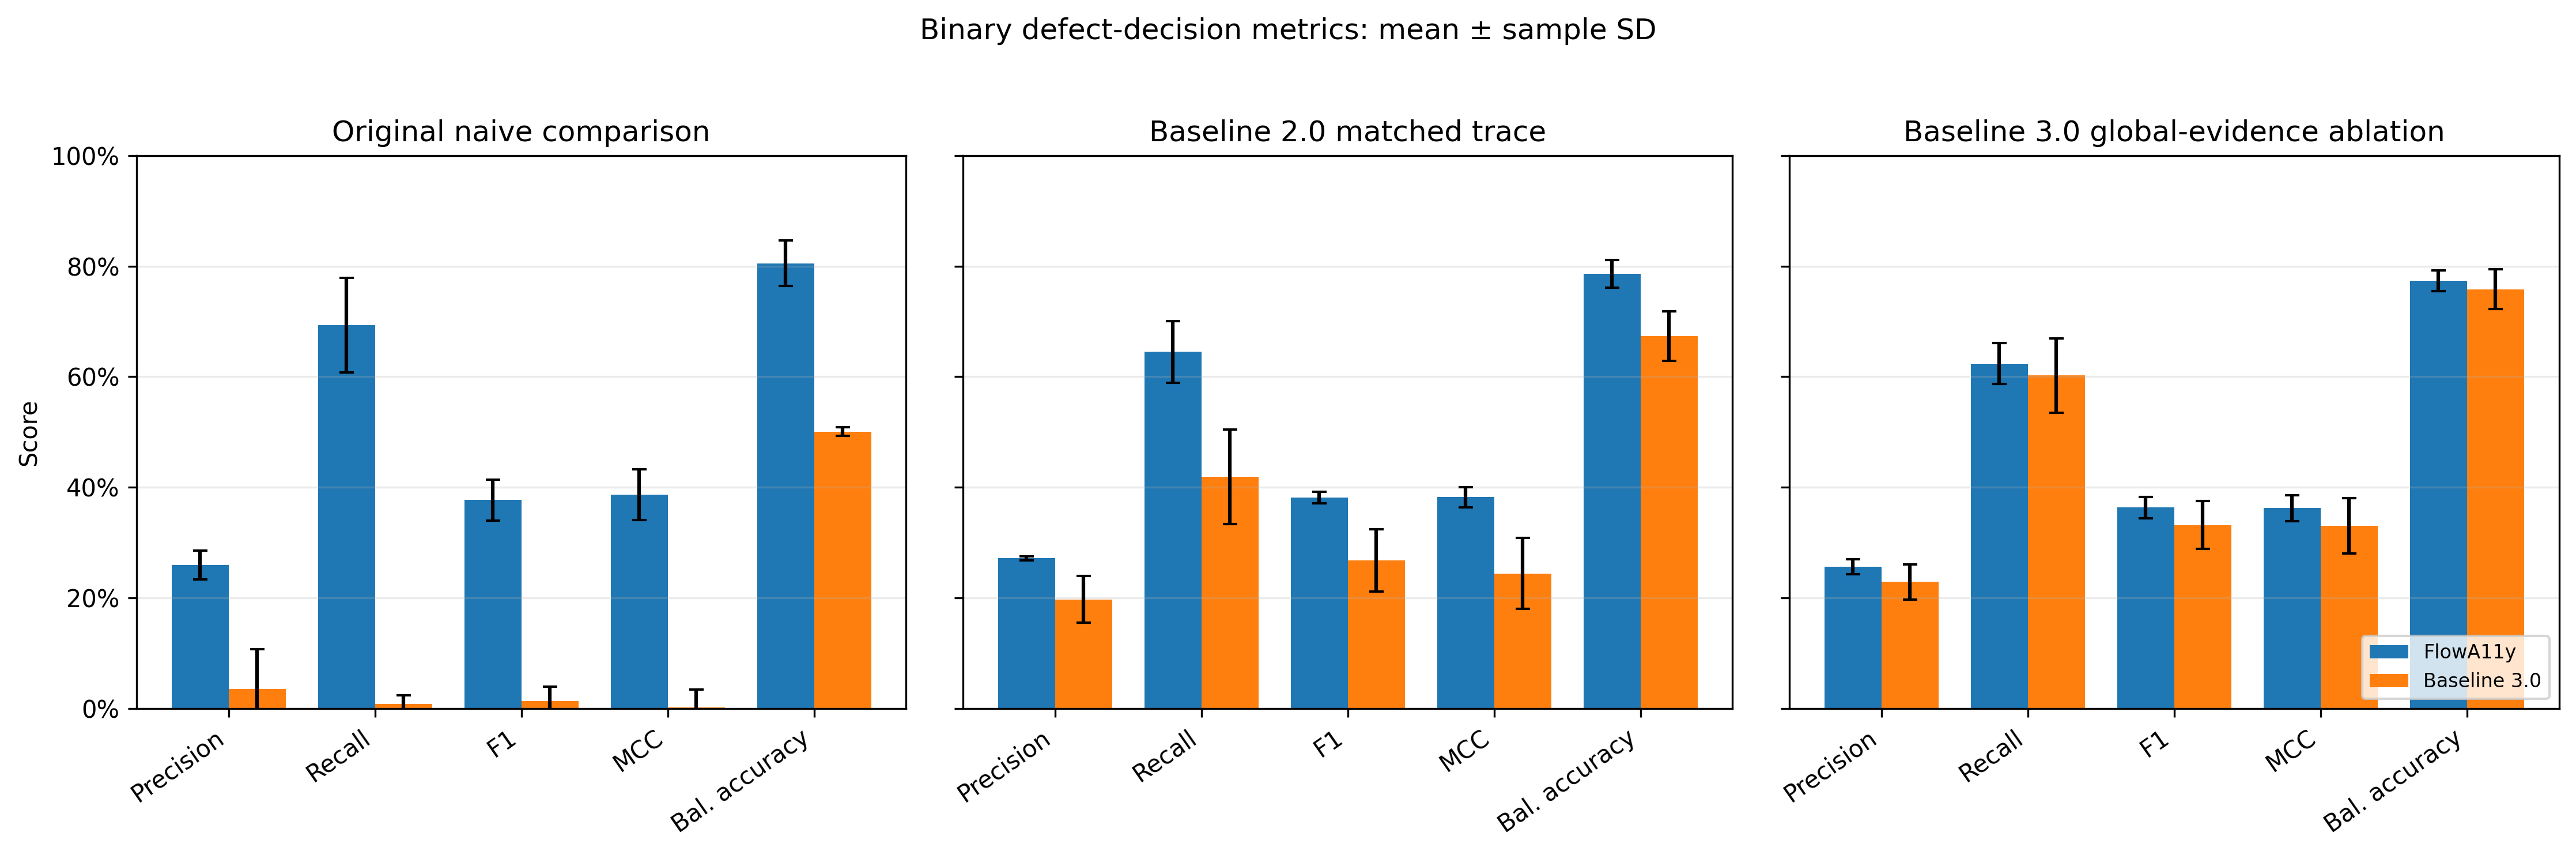

### `binary_matched_paired_deltas.png`

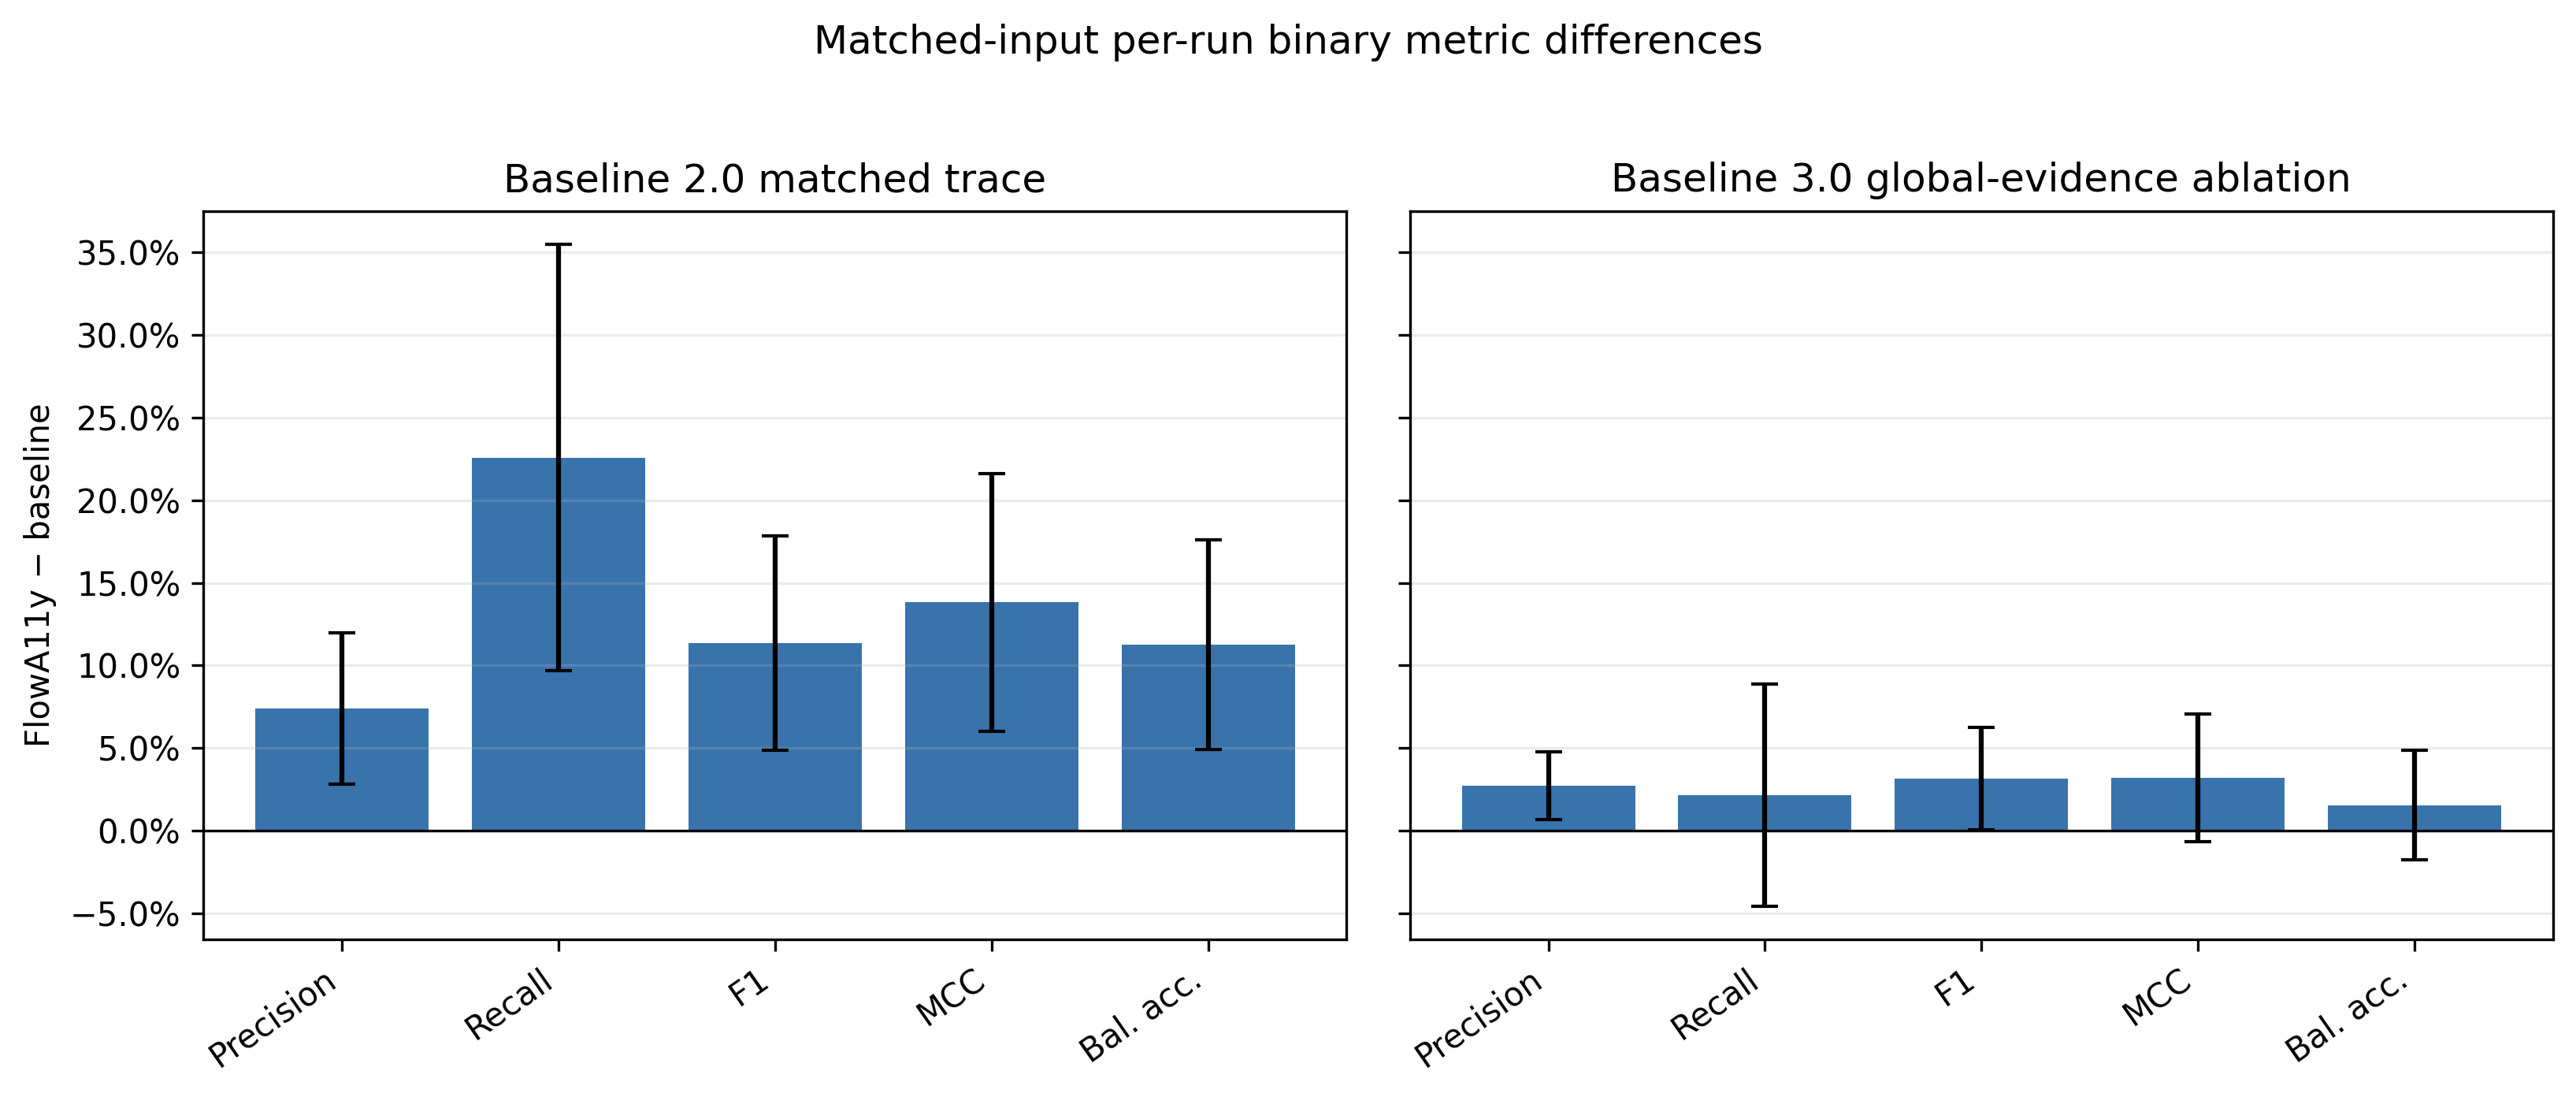

### `binary_not_trigger_reason_composition.png`

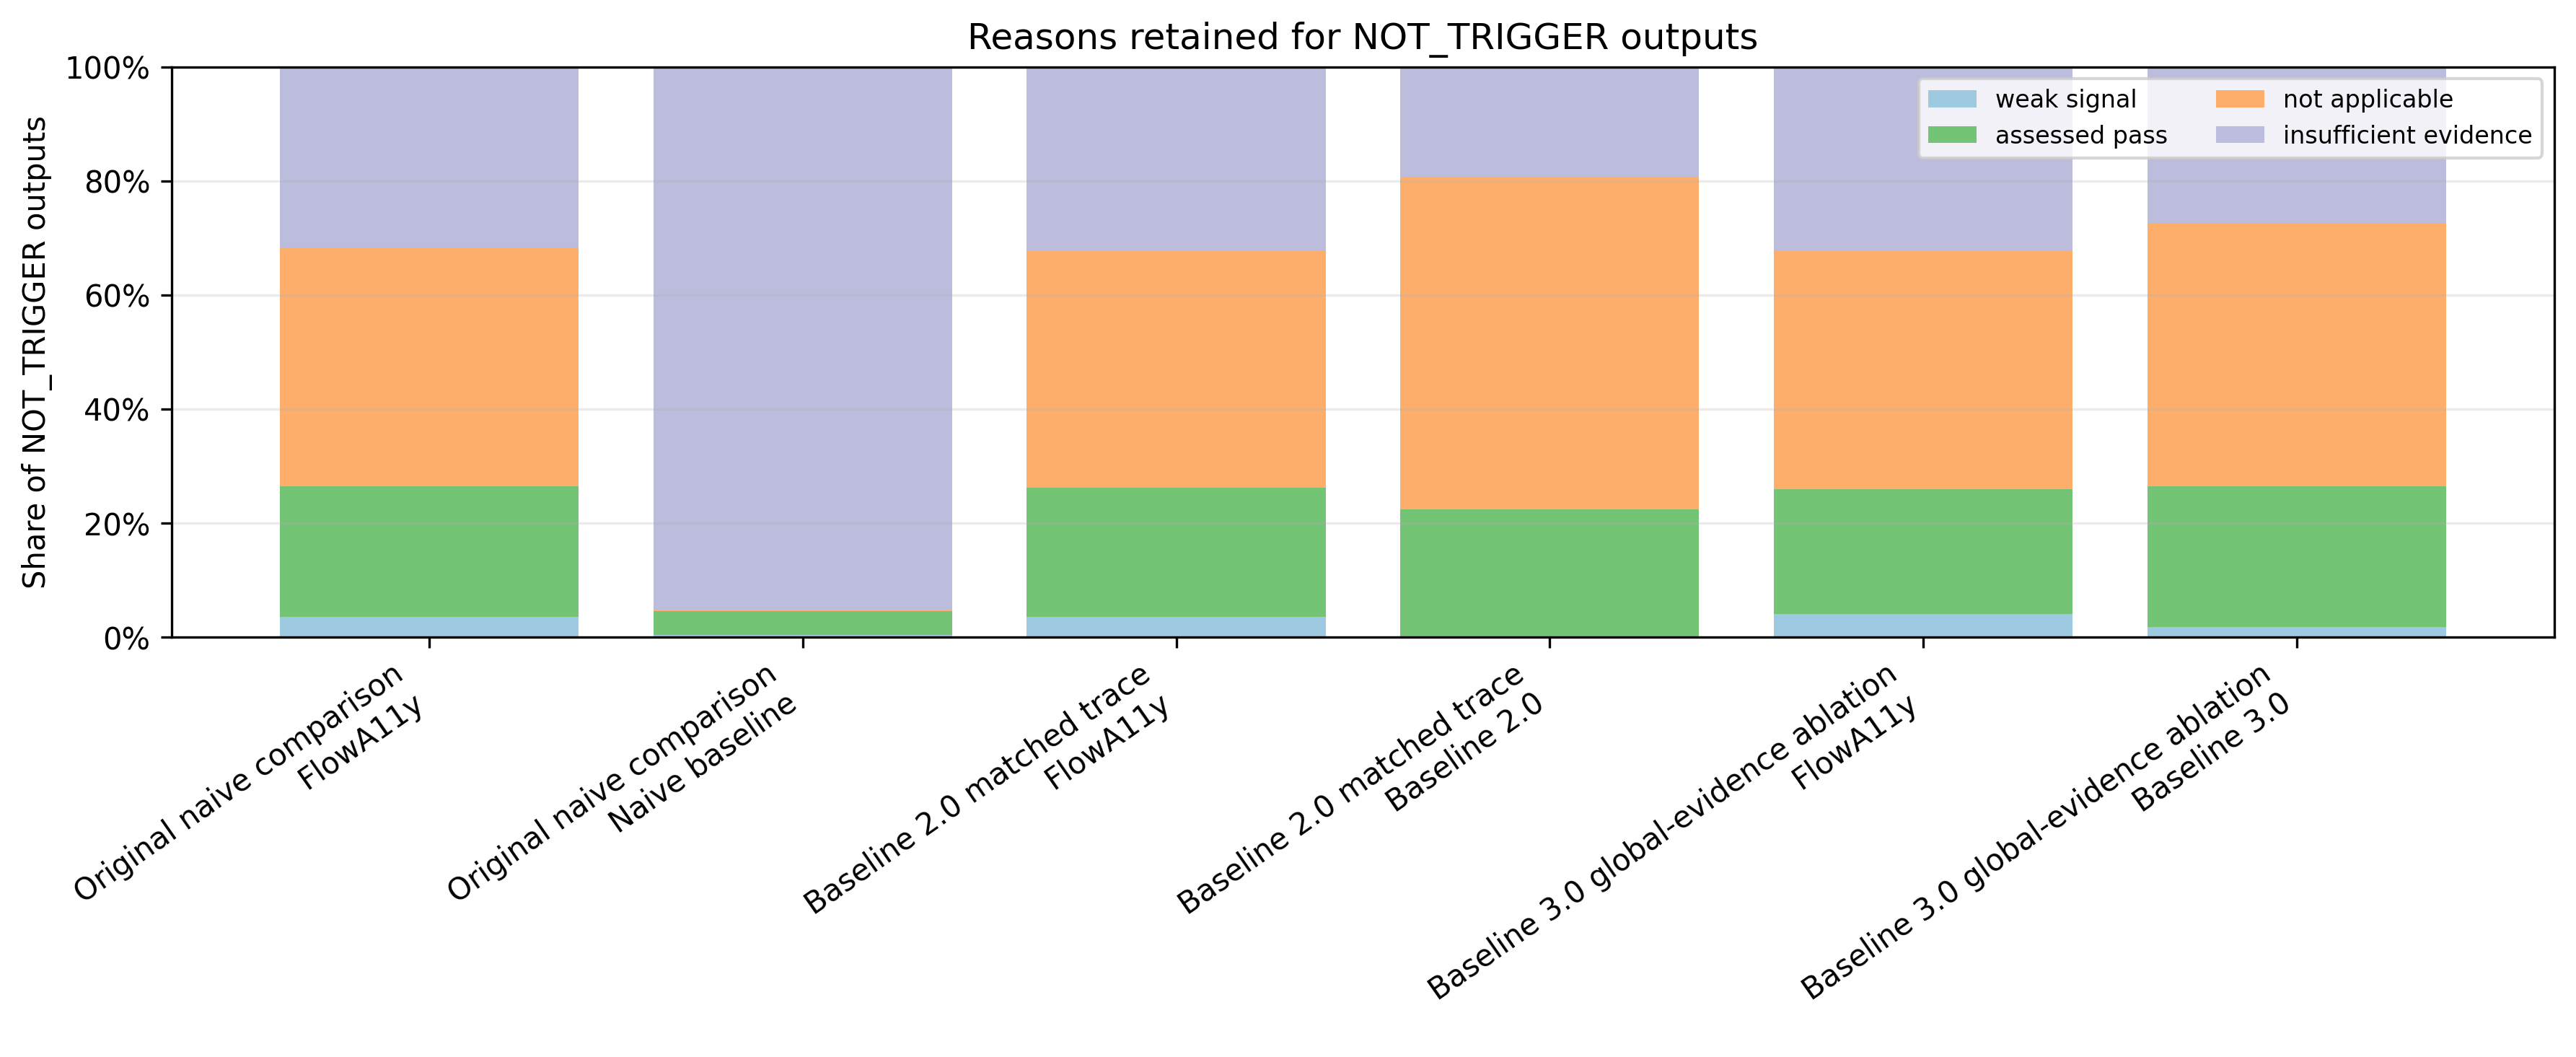

### `binary_trigger_not_trigger_rates.png`

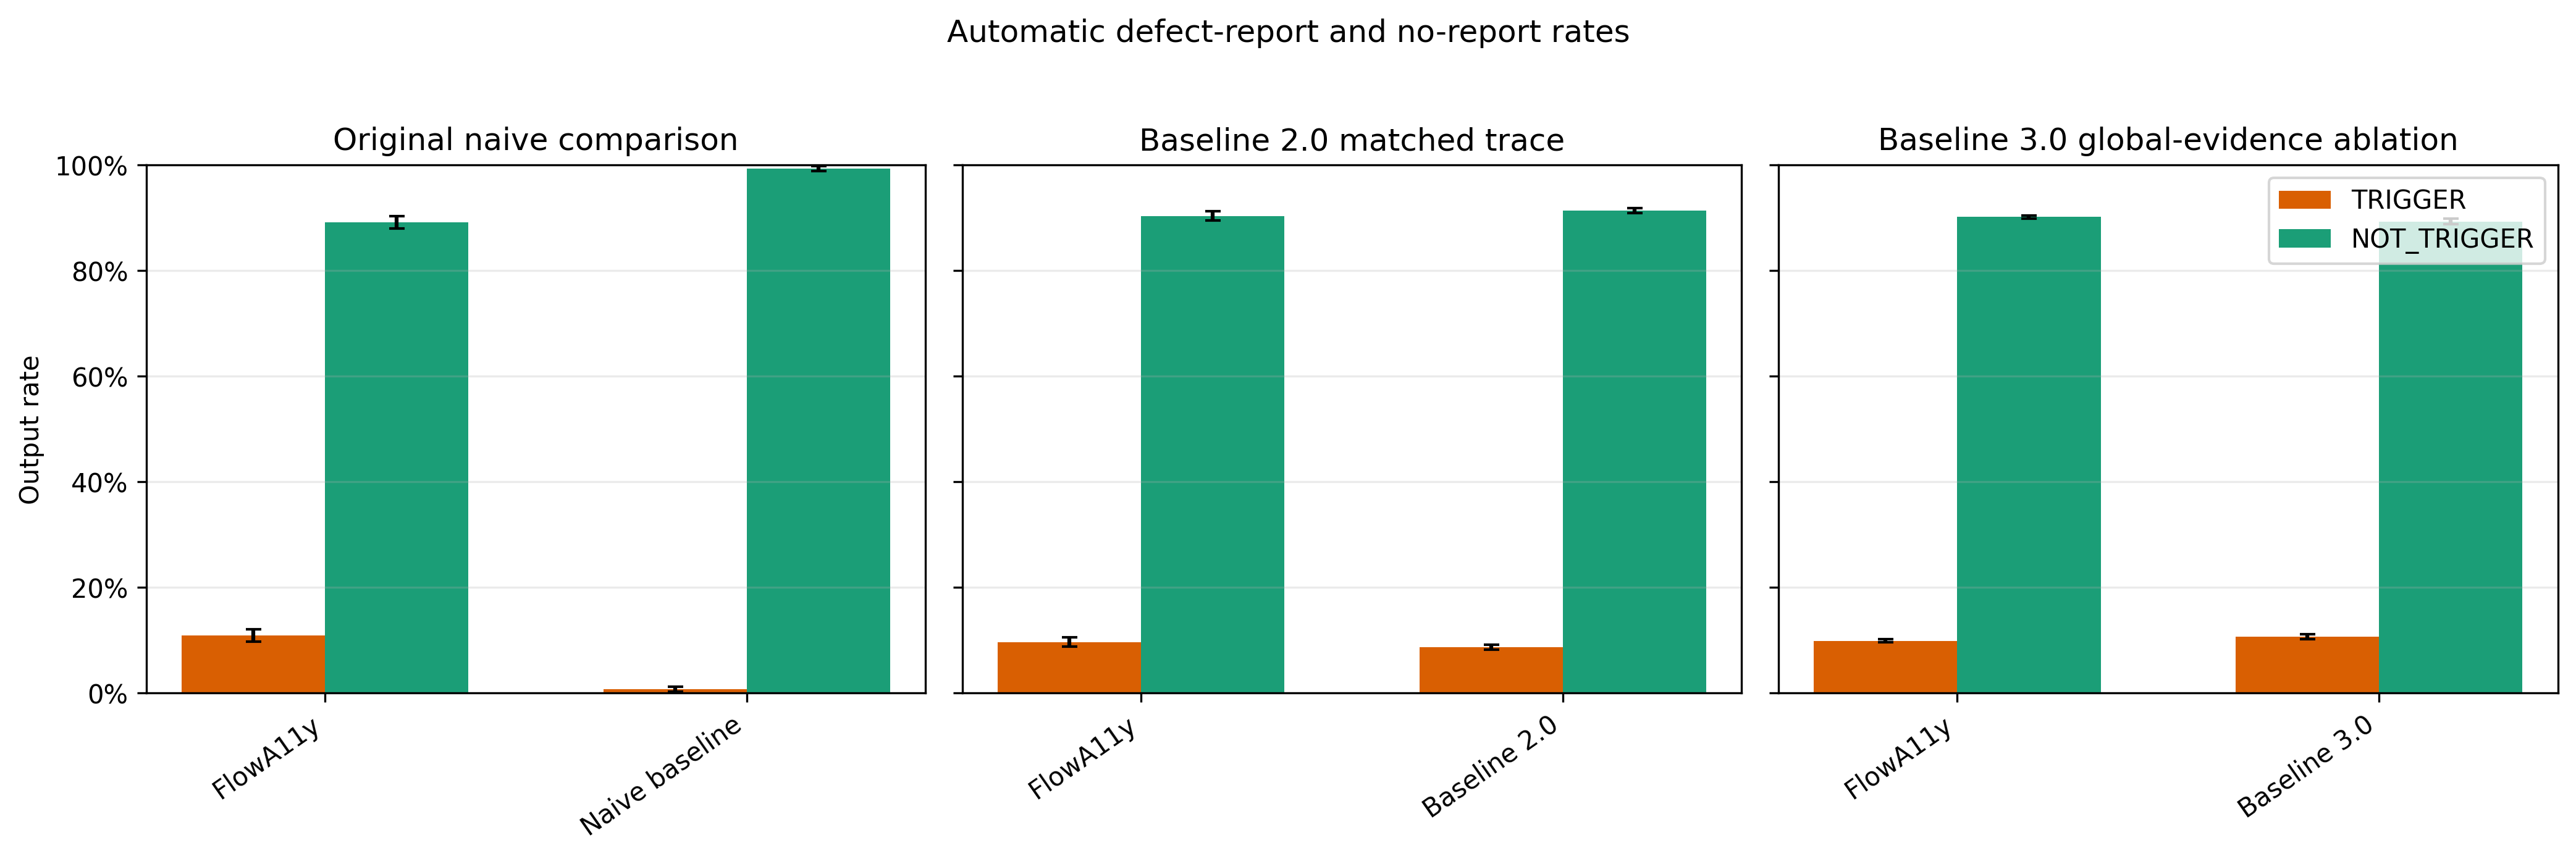

In [5]:
figure_dir = output_dir / "figures"
for filename in [
    "binary_metrics_by_cohort.png",
    "binary_matched_paired_deltas.png",
    "binary_not_trigger_reason_composition.png",
    "binary_trigger_not_trigger_rates.png",
]:
    display(Markdown(f"### `{filename}`"))
    display(Image(filename=str(figure_dir / filename)))